# Agent自编排loop流

# or运算 ` | ` (管道符连接Rennable组件) 的硬编排固定流程

技术点：prompts模板可以将模板内容转化成各种格式的数据，包括Messages。本质是一种加工工厂。

In [12]:
from langchain_core.prompts import ChatPromptTemplate, PromptTemplate, MessagesPlaceholder
from langchain_core.messages import HumanMessage, AIMessage
from langchain_ollama import ChatOllama
from langchain_core.runnables import RunnableConfig, ConfigurableField

PromptTemplate模型(LLM)消息模板

In [ ]:
prompt = PromptTemplate.from_template({
    "{add} + {added}"
})

In [ ]:
dir(PromptTemplate)

ChatPromptTemplate聊天模板

MessagePlaceholder消息占位

In [8]:
template = ChatPromptTemplate.from_messages(
    [
        {"role": "system", "content": "{a}"},
        MessagesPlaceholder(variable_name="chat_history"),  # 代表消息占位, 将数据库的历史数据加入其中
        {"role": "user", "content": "{b}"}
    ]
)

# 历史数据
history = [
    HumanMessage("历史的用户问题"),
    AIMessage("历史的AI回答数据")
]

final_message = template.invoke({  # 实际是from_messages
    "a": "a",
    "b": "b",
    "chat_history": history
}).messages
final_message

[SystemMessage(content='a', additional_kwargs={}, response_metadata={}),
 HumanMessage(content='历史的用户问题', additional_kwargs={}, response_metadata={}),
 AIMessage(content='历史的AI回答数据', additional_kwargs={}, response_metadata={}, tool_calls=[], invalid_tool_calls=[]),
 HumanMessage(content='b', additional_kwargs={}, response_metadata={})]

## 链式表达

In [13]:
model_name = "qwen2.5:7b-instruct-q4_K_M"

template = ChatPromptTemplate.from_messages([
    ("system", "你是{role}。"),
    ("user", "{question}")
])

model = ChatOllama(model="qwen3.5:0.8b").configurable_fields(
    model=ConfigurableField(
        id="model",
        description="The name of the model to use.",  
    ),
    temperature=ConfigurableField(
        id="temperature",
        description="The temperature to use for sampling.",
    )
)

config = RunnableConfig(
    model=model_name,
    temperature=0.8
)

chain = template | model

In [14]:
result = chain.invoke(
    {
        "role": "贴心小助手",
        "question": "说说话。"
    },
    config=config
)
result

AIMessage(content='当然可以！聊天是一种很好的放松方式。你想聊些什么呢？是工作上的事情，生活中的趣事，还是有什么特别的话题想分享？或者，如果你什么都不想聊，我们也可以随便聊聊日常琐事、趣闻或者科普知识。', additional_kwargs={}, response_metadata={'model': 'qwen2.5:7b-instruct-q4_K_M', 'created_at': '2026-08-27T02:18:22.2542566Z', 'done': True, 'done_reason': 'stop', 'total_duration': 11544501400, 'load_duration': 9745073300, 'prompt_eval_count': 21, 'prompt_eval_duration': 229562000, 'eval_count': 53, 'eval_duration': 1561857000, 'logprobs': None, 'model_name': 'qwen2.5:7b-instruct-q4_K_M', 'model_provider': 'ollama'}, id='lc_run--01a04102-b193-7b30-aa3e-5d5a819342a0-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 21, 'output_tokens': 53, 'total_tokens': 74})

# 定制状态图

核心: 状态定义(stateT)、定义业务节点(active_node)、定义边(普通边[实体边]、条件边)、设置进入点，终止点、图编译(complie)

## 1. 复现简单Agent

In [19]:
from langchain_ollama import ChatOllama
from langgraph.graph import StateGraph, END
from typing import Annotated, TypedDict, Literal
from langgraph.checkpoint.memory import MemorySaver
from langchain_core.messages import BaseMessage, HumanMessage, AIMessage
from langgraph.graph.message import add_messages
from langchain_core.runnables import RunnableConfig, ConfigurableField

模型

In [ ]:
model_name = "qwen2.5:7b-instruct-q4_K_M"

config = RunnableConfig(
    configurable={
        "thread_id": "01"
    }
)

model = ChatOllama(model=model_name)

工具

In [38]:
from langchain.tools import tool
@tool
def multiply(a: int, b: int) -> int:
    """将 `a` 和 `b` 相乘。

    参数:
        a: 第一个整型
        b: 第二个整型
    """
    return a * b

@tool
def add(a: int, b: int) -> int:
    """将 `a` 和 `b` 相加。

    参数:
        a: 第一个整型
        b: 第二个整型
    """
    return a + b

@tool
def divide(a: int, b: int) -> float:
    """将 `a` 和 `b` 相除。

    参数:
        a: 第一个整型
        b: 第二个整型
    """
    return a / b

In [50]:
tools = [add, multiply, divide]
tools_by_name = {tool.name: tool for tool in tools}
model_with_tools = model.bind_tools(tools)

In [40]:
def exec_tool_node(tool, **kwargs):
    func = tool
    return func.invoke(**kwargs)

构图

In [41]:
class AgentState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]
    
    is_toolcall: bool
    
    tool_names: list
    tool_params: list
    tool_ids: list
    tool_call_time: int
    # tool_result: list[dict]
    
    done: bool
    
    iteration: int
    llm_calls: int

    state_result: bool

定义节点

In [51]:
def LLM_node(state: AgentState, , config: RunnableConfig) -> dict:
    outputs = model_with_tools.invoke(
        state.get("messages"),
        config=config
    )
    if outputs.tool_calls:
        tool_name_list = []
        tool_params_list = []
        tool_id_list = []
        for tool_call in outputs.tool_calls:
            tool_name_list.append(tool_call.get("name"))
            tool_params_list.append(tool_call.get("args"))
            tool_id_list.append(tool_call.get("id"))
        return {
            "messages": outputs,
            "llm_calls": state.get("llm_calls", 0) + 1,
            "is_toolcall": True,
            "tool_names": tool_name_list,
            "tool_params": tool_params_list,
            "tool_id": tool_id_list
        }
    else:
        if state.get("iteration") < 3:
            return {
                "is_toolcall": False,
                "llm_calls": state.get("llm_calls", 0) + 1,
                "iteration": state.get("iteration", 0) + 1
            }
        else:
            return {
                "done": True,
                "llm_calls": state.get("llm_calls", 0) + 1,
                "state_result": False
            }

In [43]:
def fail_deal(state: AgentState) -> dict:
    if state.get("done", False) and state.get("state_result", True):
        error_message = AIMessage(content="工具调用出现错误。")
        return {
            'messages': error_message
        }
    return {}

In [44]:
def tool_call_node(state: AgentState) -> dict:
    tool_results = []
    # 工具处理逻辑自定义
    tool_call_time = 0
    for tool_call in state['messages'][-1].tool_calls:
        result = exec_tool_node(tool_call.name, tool_call["args"])
        tool_results.append(ToolMessage(content=result, tool_call_id=tool_call["id"])) # 定义工具id，防止反复调用
        tool_call_time += 1
    return {
        "messages": tool_results,
        "tool_call_time": state.get("tool_call_time", 0) + tool_call_time
    }

In [45]:
def router(state: AgentState) -> Literal["TOOL", END]:
    if state.get("done", False):
        return END
    elif not state.get("done", False) and state.get("is_toolcall", False):
        return "TOOL"

In [52]:
memory = MemorySaver()
graph = StateGraph(AgentState)

graph.add_node("FAIL_DEAL", fail_deal)
graph.add_node("LLM", LLM_node)
graph.add_node("TOOL", tool_call_node)

graph.set_entry_point("FAIL_DEAL")
graph.add_edge("FAIL_DEAL", "LLM")
graph.add_conditional_edges("LLM", router, ["TOOL", END])
graph.add_edge("TOOL", "LLM")

app = graph.compile(checkpointer=memory)

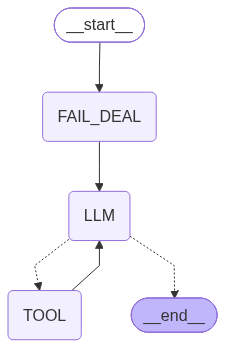

In [53]:
app

In [ ]:
messages = [HumanMessage(content="3 和 4相加，然后乘以5，除以4")]
messages = app.invoke({"messages": messages}, , config=config)
for m in messages["messages"]:
    m.pretty_print()